<a href="https://colab.research.google.com/github/Neha-7812/Python-Data-Science-Fundamentals/blob/main/Student_Performance_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries Imported Successfully!")


Libraries Imported Successfully!


In [2]:

# Load Dataset

url = "https://raw.githubusercontent.com/Neha-7812/Python-Data-Science-Fundamentals/main/StudentsPerformance.csv"

df = pd.read_csv(url)

print("Dataset Loaded Successfully!")
print(df.head())


Dataset Loaded Successfully!
   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test preparation course  math score  reading score  writing score  
0                    none          72             72             74  
1               completed          69             90             88  
2                    none          90             95             93  
3                    none          47             57             44  
4                    none          76             78             75  


In [3]:

# Dataset Information

print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())


Dataset Shape: (1000, 8)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB

Statistical Summary:
       math score  reading score  writing score
count  1000.00000    1000.000000    1000.000000
mean     66.08900      69.169000      68.054000
std      15.16308      14.600192      15.195657
min       0.0

In [4]:

# Check Missing Values

print("Missing Values:")
print(df.isnull().sum())

# Remove Duplicate Records
df = df.drop_duplicates()

# Fill Missing Values
df = df.fillna(df.mode().iloc[0])

print("\nData Cleaning Completed!")
print("Dataset Shape:", df.shape)


Missing Values:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

Data Cleaning Completed!
Dataset Shape: (1000, 8)


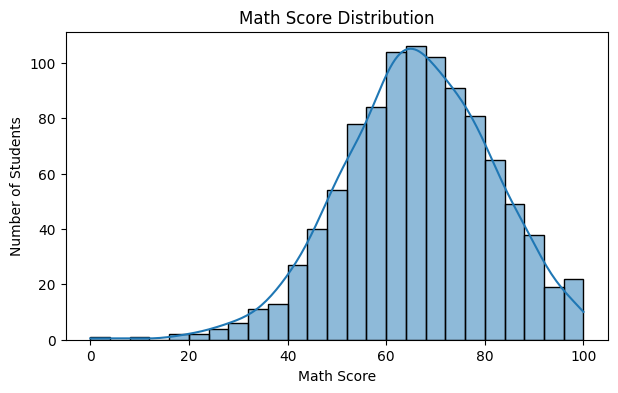

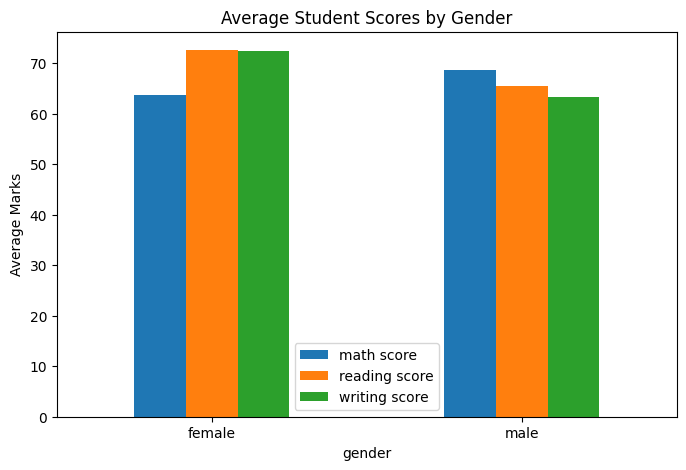

In [5]:

# Data Visualization

# 1. Math Score Distribution
plt.figure(figsize=(7, 4))
sns.histplot(df['math score'], kde=True)
plt.title("Math Score Distribution")
plt.xlabel("Math Score")
plt.ylabel("Number of Students")
plt.show()

# 2. Average Scores by Gender
df.groupby('gender')[['math score', 'reading score', 'writing score']].mean().plot(kind='bar', figsize=(8, 5))

plt.title("Average Student Scores by Gender")
plt.ylabel("Average Marks")
plt.xticks(rotation=0)
plt.show()


In [6]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Convert categorical data into numerical data
df_encoded = df.copy()

le = LabelEncoder()

for column in df_encoded.select_dtypes(include=['object']).columns:
    df_encoded[column] = le.fit_transform(df_encoded[column])

# Select Input Features
X = df_encoded.drop('math score', axis=1)

# Select Target
y = df_encoded['math score']

# Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Data Prepared Successfully!")
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Data Prepared Successfully!
Training Data: (800, 7)
Testing Data: (200, 7)


In [7]:

from sklearn.linear_model import LinearRegression

# Create Model
model = LinearRegression()

# Train Model
model.fit(X_train, y_train)

# Predict Results
y_pred = model.predict(X_test)

print("Model Training Completed Successfully!")
print("Predicted Math Scores:")
print(y_pred[:10])


Model Training Completed Successfully!
Predicted Math Scores:
[77.11855699 57.07358    79.35766788 77.15093246 84.91283746 79.85882914
 64.42312794 52.47379147 74.61139924 50.01079481]


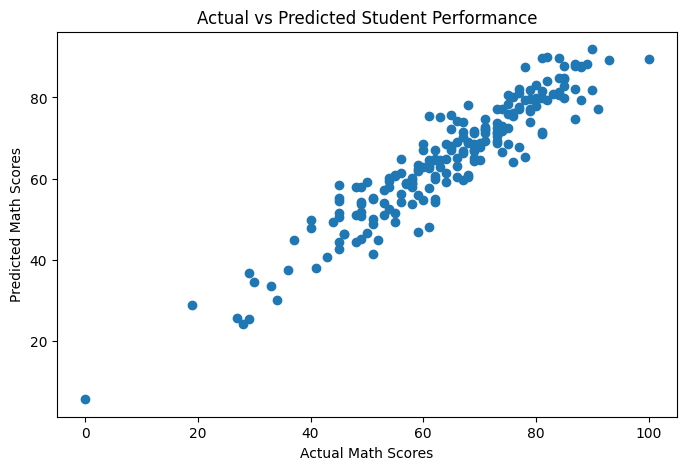

In [8]:

# Actual vs Predicted Scores

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Math Scores")
plt.ylabel("Predicted Math Scores")
plt.title("Actual vs Predicted Student Performance")

plt.show()
